### Define Business Problem & Experiment Hypothesis
Business problem:

Many users sign up for the developer platform but do not adopt API Monitoring. The product team wants to test whether an improved onboarding experience encourages more users to adopt this feature.

Proposed experiment:
- Control group: Users receive the existing onboarding experience.
- Treatment group: Users receive a new onboarding experience with API Monitoring guidance.
Research question:

Does the new onboarding experience increase API Monitoring adoption within 30 days?

### Define the experiment :

In [28]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Experiment information
experiment_name = "API Monitoring Onboarding Experiment"

business_problem = (
    "Many developer-tool users do not adopt API Monitoring "
    "after signing up."
)

research_question = (
    "Does the new onboarding experience increase API Monitoring "
    "adoption within 30 days?"
)

control_group = "Existing onboarding experience"

treatment_group = "New onboarding with API Monitoring guidance"

primary_metric = "30-day API Monitoring adoption rate"

observation_window = "30 days"

# Display experiment definition
print("EXPERIMENT:", experiment_name)
print("\nBUSINESS PROBLEM:", business_problem)
print("\nRESEARCH QUESTION:", research_question)
print("\nCONTROL GROUP:", control_group)
print("\nTREATMENT GROUP:", treatment_group)
print("\nPRIMARY METRIC:", primary_metric)
print("\nOBSERVATION WINDOW:", observation_window)

EXPERIMENT: API Monitoring Onboarding Experiment

BUSINESS PROBLEM: Many developer-tool users do not adopt API Monitoring after signing up.

RESEARCH QUESTION: Does the new onboarding experience increase API Monitoring adoption within 30 days?

CONTROL GROUP: Existing onboarding experience

TREATMENT GROUP: New onboarding with API Monitoring guidance

PRIMARY METRIC: 30-day API Monitoring adoption rate

OBSERVATION WINDOW: 30 days


### Define hypotheses

In [2]:
alpha = 0.05

H0 = "p_treatment = p_control"
H1 = "p_treatment != p_control"

print("Null Hypothesis (H0):", H0)
print("Alternative Hypothesis (H1):", H1)
print("Significance Level:", alpha)

Null Hypothesis (H0): p_treatment = p_control
Alternative Hypothesis (H1): p_treatment != p_control
Significance Level: 0.05


### Design Treatment and Control Groups

Objective: Divide eligible users into two groups so that we can fairly compare their adoption rates.

Group assignment:
- Control Group (50%): Users receive the existing onboarding experience.
- Treatment Group (50%): Users receive the new onboarding experience with API Monitoring guidance.
Both groups will be observed for 30 days after assignment.

#### Load the user dataset

In [3]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd()

# Search for users.csv inside the project
user_files = list(project_root.rglob("users.csv"))

print("Users dataset files found:")

for file in user_files:
    print(file)

Users dataset files found:


#### Find the users dataset

In [5]:
from pathlib import Path

# Check the current working directory
print("Current Working Directory:")
print(Path.cwd())

# Search the entire project directory
project_root = Path.cwd().parent.parent.parent

print("\nProject Root:")
print(project_root)

# Find all CSV files in the project
csv_files = list(project_root.rglob("*.csv"))

print("\nCSV Files Found:")

for file in csv_files:
    print(file)

Current Working Directory:
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\03_ab_testing

Project Root:
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics

CSV Files Found:
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\data\api_performance.csv
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\data\api_performance_correlation_matrix.csv
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\data\api_performance_eda_report.csv
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\data\business_api_performance_ranking.csv
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\data\business_engagement_summary.csv
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\data\business_insights_dataset_summary.csv
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\data\business_recommendations.csv
C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics

#### Review the dataset

In [8]:
from pathlib import Path
import pandas as pd

# Define project root explicitly
project_root = Path(
    r"C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics"
)

# Define users dataset path
users_path = (
    project_root / "data" / "synthetic" / "users.csv"
)

# Verify file exists
print("File exists:", users_path.exists())
print("Dataset path:", users_path)

# Load dataset
users = pd.read_csv(users_path)

print("\nDataset Shape:", users.shape)

display(users.head())

print("\nColumn Names:")
print(users.columns.tolist())

File exists: True
Dataset path: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\data\synthetic\users.csv

Dataset Shape: (10000, 7)


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified
0,1,283,2025-04-03,USA,Founder,Social Media,1
1,2,591,2024-06-23,Germany,Admin,Referral,1
2,3,72,2025-12-27,Japan,Founder,Referral,1
3,4,1287,2024-12-28,Canada,Admin,Paid Ads,0
4,5,703,2025-10-14,Germany,Founder,Paid Ads,1



Column Names:
['user_id', 'organization_id', 'signup_date', 'country', 'user_role', 'acquisition_channel', 'is_verified']


#### Check signup dates and user eligibility

In [9]:
# Convert signup_date to datetime
users["signup_date"] = pd.to_datetime(
    users["signup_date"],
    errors="coerce"
)

# Check signup date range
print("Earliest Signup Date:")
print(users["signup_date"].min())

print("\nLatest Signup Date:")
print(users["signup_date"].max())

# Check missing values
print("\nMissing Values:")
display(users.isna().sum())

# Check duplicate user IDs
print("\nDuplicate User IDs:")
print(users["user_id"].duplicated().sum())

# Check unique users
print("\nUnique Users:")
print(users["user_id"].nunique())

Earliest Signup Date:
2024-01-08 00:00:00

Latest Signup Date:
2026-06-23 00:00:00

Missing Values:


user_id                0
organization_id        0
signup_date            0
country                0
user_role              0
acquisition_channel    0
is_verified            0
dtype: int64


Duplicate User IDs:
0

Unique Users:
10000


#### Inspect experiment outcome data

In [10]:
# Load existing experiment datasets
assignments_path = (
    project_root / "data" / "synthetic"
    / "experiment_assignments.csv"
)

outcomes_path = (
    project_root / "data" / "synthetic"
    / "experiment_outcomes.csv"
)

assignments = pd.read_csv(assignments_path)
outcomes = pd.read_csv(outcomes_path)

print("ASSIGNMENTS DATASET")
print("Shape:", assignments.shape)
display(assignments.head())

print("\nAssignment Columns:")
print(assignments.columns.tolist())

print("\nOUTCOMES DATASET")
print("Shape:", outcomes.shape)
display(outcomes.head())

print("\nOutcome Columns:")
print(outcomes.columns.tolist())

ASSIGNMENTS DATASET
Shape: (6000, 5)


,assignment_id,experiment_id,user_id,variant,assigned_at
0,1,EXP_FEATURE_ONBOARDING_001,6253,Control,2025-08-05
1,2,EXP_FEATURE_ONBOARDING_001,4685,Treatment,2026-10-30
2,3,EXP_FEATURE_ONBOARDING_001,1732,Control,2026-10-25
3,4,EXP_FEATURE_ONBOARDING_001,4743,Treatment,2025-10-19
4,5,EXP_FEATURE_ONBOARDING_001,4522,Control,2024-10-07



Assignment Columns:
['assignment_id', 'experiment_id', 'user_id', 'variant', 'assigned_at']

OUTCOMES DATASET
Shape: (6000, 8)


,outcome_id,assignment_id,user_id,sdk_integrated,first_api_request,adopted_feature,retained_d7,measured_at
0,1,1,6253,1,0,1,1,2025-08-12
1,2,2,4685,0,1,1,1,2026-11-06
2,3,3,1732,0,0,0,0,2026-11-01
3,4,4,4743,1,1,0,0,2025-10-26
4,5,5,4522,1,1,0,1,2024-10-14



Outcome Columns:
['outcome_id', 'assignment_id', 'user_id', 'sdk_integrated', 'first_api_request', 'adopted_feature', 'retained_d7', 'measured_at']


#### Validate Experiment Assignment and Outcomes

In [11]:
# Check experiment IDs
print("Experiment IDs:")
display(assignments["experiment_id"].value_counts())

# Check treatment and control distribution
print("\nExperiment Group Distribution:")
display(assignments["variant"].value_counts())

print("\nGroup Percentages:")
display(
    assignments["variant"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Check duplicate assignments
print("\nDuplicate Assignment IDs:")
print(assignments["assignment_id"].duplicated().sum())

print("\nDuplicate User Assignments:")
print(assignments["user_id"].duplicated().sum())

# Check duplicate outcomes
print("\nDuplicate Outcome Assignment IDs:")
print(outcomes["assignment_id"].duplicated().sum())

# Check date ranges
assignments["assigned_at"] = pd.to_datetime(
    assignments["assigned_at"]
)

outcomes["measured_at"] = pd.to_datetime(
    outcomes["measured_at"]
)

print("\nAssignment Date Range:")
print(assignments["assigned_at"].min())
print(assignments["assigned_at"].max())

print("\nOutcome Measurement Date Range:")
print(outcomes["measured_at"].min())
print(outcomes["measured_at"].max())

# Check time between assignment and measurement
experiment_check = assignments[
    ["assignment_id", "user_id", "variant", "assigned_at"]
].merge(
    outcomes[
        ["assignment_id", "user_id", "adopted_feature",
         "retained_d7", "measured_at"]
    ],
    on="assignment_id",
    how="left",
    suffixes=("_assignment", "_outcome"),
    validate="one_to_one"
)

experiment_check["measurement_days"] = (
    experiment_check["measured_at"]
    - experiment_check["assigned_at"]
).dt.days

print("\nMeasurement Delay Distribution:")
display(
    experiment_check["measurement_days"]
    .value_counts()
    .sort_index()
)

Experiment IDs:


experiment_id
EXP_FEATURE_ONBOARDING_001    6000
Name: count, dtype: int64


Experiment Group Distribution:


variant
Treatment    3003
Control      2997
Name: count, dtype: int64


Group Percentages:


variant
Treatment    50.05
Control      49.95
Name: proportion, dtype: float64


Duplicate Assignment IDs:
0

Duplicate User Assignments:
0

Duplicate Outcome Assignment IDs:
0

Assignment Date Range:
2024-03-05 00:00:00
2026-10-31 00:00:00

Outcome Measurement Date Range:
2024-03-12 00:00:00
2026-11-07 00:00:00

Measurement Delay Distribution:


measurement_days
7    6000
Name: count, dtype: int64

### Validate outcome distribution by experiment group

In [12]:
# Merge assignments and outcomes
experiment_data = assignments.merge(
    outcomes,
    on=["assignment_id", "user_id"],
    how="inner",
    validate="one_to_one"
)

# Adoption distribution by group
adoption_distribution = pd.crosstab(
    experiment_data["variant"],
    experiment_data["adopted_feature"],
    margins=True
)

print("Adoption Distribution:")
display(adoption_distribution)

# Adoption rate by group
adoption_summary = (
    experiment_data
    .groupby("variant")
    .agg(
        total_users=("user_id", "nunique"),
        adopted_users=("adopted_feature", "sum"),
        adoption_rate=("adopted_feature", "mean")
    )
    .reset_index()
)

adoption_summary["adoption_rate_pct"] = (
    adoption_summary["adoption_rate"] * 100
)

print("\nAdoption Rate by Group:")
display(adoption_summary.round(4))

Adoption Distribution:


adopted_feature,0,1,All
variant,,,
Control,1623,1374,2997
Treatment,1052,1951,3003
All,2675,3325,6000



Adoption Rate by Group:


,variant,total_users,adopted_users,adoption_rate,adoption_rate_pct
0,Control,2997,1374,0.4585,45.8458
1,Treatment,3003,1951,0.6497,64.9684


#### Calculate Initial Experiment Lift

In [13]:
# Extract adoption rates
control_rate = adoption_summary.loc[
    adoption_summary["variant"] == "Control",
    "adoption_rate"
].iloc[0]

treatment_rate = adoption_summary.loc[
    adoption_summary["variant"] == "Treatment",
    "adoption_rate"
].iloc[0]

# Calculate absolute lift
absolute_lift = treatment_rate - control_rate

# Calculate relative lift
relative_lift = (
    (treatment_rate - control_rate) / control_rate
) * 100

print("Control Adoption Rate:", round(control_rate * 100, 2), "%")
print("Treatment Adoption Rate:", round(treatment_rate * 100, 2), "%")

print("\nAbsolute Lift:", round(absolute_lift * 100, 2), "percentage points")
print("Relative Lift:", round(relative_lift, 2), "%")

Control Adoption Rate: 45.85 %
Treatment Adoption Rate: 64.97 %

Absolute Lift: 19.12 percentage points
Relative Lift: 41.71 %


### Define Primary and Secondary Metrics

Experiment metrics
1. Primary metric — 7-day API Monitoring adoption rate: Percentage of assigned users who adopted the feature within the experiment's 7-day measurement window.
2. Secondary metric — 7-day retention rate: Percentage of assigned users who returned or remained active after 7 days, represented by retained_d7.
3. Secondary metric — SDK integration rate: Percentage of assigned users who integrated the SDK, represented by sdk_integrated.
4. Secondary metric — First API request rate: Percentage of assigned users who made their first API request, represented by first_api_request.

In [23]:
# Calculate Primary and Secondary Experiment Metrics

experiment_metrics = (
    experiment_data
    .groupby("variant")
    .agg(
        total_users=("user_id", "nunique"),
        adoption_rate=("adopted_feature", "mean"),
        sdk_integration_rate=("sdk_integrated", "mean"),
        first_api_request_rate=("first_api_request", "mean"),
        retention_d7_rate=("retained_d7", "mean")
    )
    .reset_index()
)

# Convert rates to percentages
rate_columns = [
    "adoption_rate",
    "sdk_integration_rate",
    "first_api_request_rate",
    "retention_d7_rate"
]

experiment_metrics[rate_columns] *= 100

display(experiment_metrics.round(2))

,variant,total_users,adoption_rate,sdk_integration_rate,first_api_request_rate,retention_d7_rate
0,Control,2997,45.85,60.19,56.52,51.05
1,Treatment,3003,64.97,75.02,70.20,57.54


#### Verify metric values and group sizes

In [22]:
# Validate Experiment Metrics

print("Experiment group sizes:")
print(experiment_data["variant"].value_counts())

print("\nMissing values in experiment metrics:")
print(
    experiment_data[
        [
            "adopted_feature",
            "sdk_integrated",
            "first_api_request",
            "retained_d7"
        ]
    ].isna().sum()
)

print("\nUnique values in binary metric columns:")
for column in [
    "adopted_feature",
    "sdk_integrated",
    "first_api_request",
    "retained_d7"
]:
    print(f"{column}: {sorted(experiment_data[column].dropna().unique())}")

Experiment group sizes:
variant
Treatment    3003
Control      2997
Name: count, dtype: int64

Missing values in experiment metrics:
adopted_feature      0
sdk_integrated       0
first_api_request    0
retained_d7          0
dtype: int64

Unique values in binary metric columns:
adopted_feature: [np.int64(0), np.int64(1)]
sdk_integrated: [np.int64(0), np.int64(1)]
first_api_request: [np.int64(0), np.int64(1)]
retained_d7: [np.int64(0), np.int64(1)]


### Two-Proportion Z-Test

Objective: Determine whether the difference in 7-day API Monitoring adoption rates between Control and Treatment is statistically significant.

We will test:
- Null hypothesis (H₀): The Control and Treatment adoption rates are equal.
- Alternative hypothesis (H₁): The Control and Treatment adoption rates are different.
- Significance level (α): 0.05
- Test type: Two-sided, two-proportion Z-test

In [21]:
# Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

# Extract adoption counts
control_data = experiment_data[
    experiment_data["variant"] == "Control"
]

treatment_data = experiment_data[
    experiment_data["variant"] == "Treatment"
]

control_adopted = control_data["adopted_feature"].sum()
treatment_adopted = treatment_data["adopted_feature"].sum()

control_total = len(control_data)
treatment_total = len(treatment_data)

# Prepare counts and sample sizes
successes = [
    treatment_adopted,
    control_adopted
]

sample_sizes = [
    treatment_total,
    control_total
]

# Perform two-sided two-proportion Z-test
z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=sample_sizes,
    alternative="two-sided"
)

print("Control Adopted Users:", control_adopted)
print("Treatment Adopted Users:", treatment_adopted)

print("\nControl Total Users:", control_total)
print("Treatment Total Users:", treatment_total)

print("\nZ-statistic:", round(z_stat, 4))
print("P-value:", p_value)

Control Adopted Users: 1374
Treatment Adopted Users: 1951

Control Total Users: 2997
Treatment Total Users: 3003

Z-statistic: 14.8999
P-value: 3.2995536625081363e-50


### Calculate the 95% Confidence Interval

In [20]:
#  Calculate 95% Confidence Interval

from statsmodels.stats.proportion import confint_proportions_2indep

# Calculate confidence interval for difference in proportions
ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_adopted,
    nobs1=treatment_total,
    count2=control_adopted,
    nobs2=control_total,
    method="newcomb",
    compare="diff",
    alpha=0.05
)

print("Observed Adoption Rate Difference:",
      round(absolute_lift * 100, 2), "percentage points")

print("\n95% Confidence Interval:")
print("Lower Bound:", round(ci_low * 100, 2), "percentage points")
print("Upper Bound:", round(ci_high * 100, 2), "percentage points")

Observed Adoption Rate Difference: 19.12 percentage points

95% Confidence Interval:
Lower Bound: 16.64 percentage points
Upper Bound: 21.57 percentage points


### Visualize the Confidence Interval

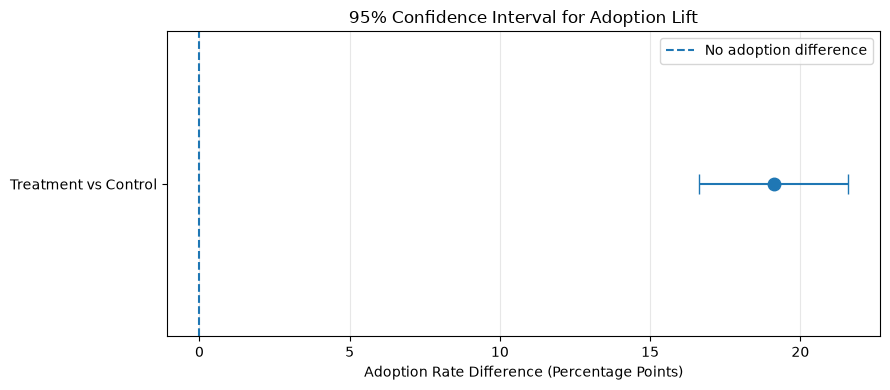

In [24]:
# Step 6: Visualize Adoption Lift and 95% Confidence Interval

import matplotlib.pyplot as plt

observed_difference = absolute_lift * 100
lower_bound = ci_low * 100
upper_bound = ci_high * 100

plt.figure(figsize=(9, 4))

plt.errorbar(
    x=observed_difference,
    y=1,
    xerr=[[
        observed_difference - lower_bound
    ], [
        upper_bound - observed_difference
    ]],
    fmt="o",
    capsize=7,
    markersize=9
)

plt.axvline(
    x=0,
    linestyle="--",
    label="No adoption difference"
)

plt.yticks([1], ["Treatment vs Control"])
plt.xlabel("Adoption Rate Difference (Percentage Points)")
plt.title("95% Confidence Interval for Adoption Lift")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Statistical Significance Decision

Objective: Make a formal decision about whether the new onboarding experience produced a statistically significant improvement in 7-day API Monitoring adoption.

We will use:
- Significance level (\(\alpha\)): 0.05
- P-value: Your calculated Z-test p-value
- Confidence interval: Your calculated 95% confidence interval

In [25]:
#  Make the Statistical Significance Decision

alpha = 0.05

print("Statistical Significance Decision")
print("----------------------------------")

if p_value < alpha:
    print("P-value:", f"{p_value:.4e}")
    print("Alpha:", alpha)
    print("\nDecision: Reject the Null Hypothesis (H0)")
    print(
        "Conclusion: There is statistically significant "
        "evidence of a difference in adoption rates."
    )
else:
    print("P-value:", f"{p_value:.4e}")
    print("Alpha:", alpha)
    print("\nDecision: Fail to Reject the Null Hypothesis (H0)")
    print(
        "Conclusion: There is insufficient statistical "
        "evidence of a difference in adoption rates."
    )

print("\nConfidence Interval:")
print(
    f"{ci_low * 100:.2f} to {ci_high * 100:.2f} "
    "percentage points"
)

if ci_low > 0:
    print("The confidence interval supports a positive adoption lift.")
elif ci_high < 0:
    print("The confidence interval supports a negative adoption lift.")
else:
    print("The confidence interval includes zero.")

Statistical Significance Decision
----------------------------------
P-value: 3.2996e-50
Alpha: 0.05

Decision: Reject the Null Hypothesis (H0)
Conclusion: There is statistically significant evidence of a difference in adoption rates.

Confidence Interval:
16.64 to 21.57 percentage points
The confidence interval supports a positive adoption lift.


### Estimate Business Impact

Objective: Estimate how many additional users could adopt API Monitoring if the Treatment experience were applied to a group of 10,000 users.

In [26]:
# Estimate Business Impact

# Hypothetical rollout population
rollout_users = 10_000

# Expected adopters under each onboarding experience
expected_control_adopters = rollout_users * control_rate
expected_treatment_adopters = rollout_users * treatment_rate

# Additional adopters from Treatment
additional_adopters = (
    expected_treatment_adopters - expected_control_adopters
)

print("Hypothetical Rollout Population:", rollout_users)

print(
    "\nExpected Adopters with Control:",
    round(expected_control_adopters)
)

print(
    "Expected Adopters with Treatment:",
    round(expected_treatment_adopters)
)

print(
    "\nEstimated Additional Adopters:",
    round(additional_adopters)
)

print(
    "Additional Adopters per 1,000 Users:",
    round(additional_adopters / rollout_users * 1000)
)

Hypothetical Rollout Population: 10000

Expected Adopters with Control: 4585
Expected Adopters with Treatment: 6497

Estimated Additional Adopters: 1912
Additional Adopters per 1,000 Users: 191


### Evaluate Experiment Validity

In [27]:
#  Experiment Validity Checks

# 1. Check unique user assignment
unique_users = experiment_data["user_id"].nunique()
total_rows = len(experiment_data)

# 2. Check assignment distribution
group_counts = experiment_data["variant"].value_counts()

# 3. Check measurement timing
measurement_delay = (
    pd.to_datetime(experiment_data["measured_at"]) -
    pd.to_datetime(experiment_data["assigned_at"])
).dt.days

# 4. Check experiment outcome completeness
outcome_columns = [
    "adopted_feature",
    "sdk_integrated",
    "first_api_request",
    "retained_d7"
]

missing_outcomes = experiment_data[outcome_columns].isna().sum()

print("EXPERIMENT VALIDITY CHECKS")
print("--------------------------")

print("\nUnique Users:", unique_users)
print("Total Experiment Rows:", total_rows)
print("Duplicate User Assignments:", total_rows - unique_users)

print("\nGroup Allocation:")
print(group_counts)

print("\nMeasurement Delay (Days):")
print(measurement_delay.value_counts().sort_index())

print("\nMissing Outcome Values:")
print(missing_outcomes)

EXPERIMENT VALIDITY CHECKS
--------------------------

Unique Users: 6000
Total Experiment Rows: 6000
Duplicate User Assignments: 0

Group Allocation:
variant
Treatment    3003
Control      2997
Name: count, dtype: int64

Measurement Delay (Days):
7    6000
Name: count, dtype: int64

Missing Outcome Values:
adopted_feature      0
sdk_integrated       0
first_api_request    0
retained_d7          0
dtype: int64


### Final A/B Testing Results and Business Recommendation

#  Final A/B Testing Results and Business Recommendation

## Executive Summary

The objective of this experiment was to evaluate whether the new API Monitoring onboarding experience improves feature adoption among developer-tool users.

The experiment compared two groups:

- **Control Group:** Users who received the existing onboarding experience.
- **Treatment Group:** Users who received the new API Monitoring onboarding experience.

A total of 6,000 users participated in the experiment. The results indicate that users exposed to the new onboarding experience demonstrated substantially higher 7-day feature adoption.

##  Final Experiment Results

| Metric | Control | Treatment |
|---|---:|---:|
| Total Users | 2,997 | 3,003 |
| Feature Adopters | 1,374 | 1,951 |
| Adoption Rate | 45.85% | 64.97% |

### Key Performance Indicators

| KPI | Result |
|---|---:|
| Absolute Adoption Lift | +19.12 percentage points |
| Relative Adoption Lift | +41.71% |
| Z-Statistic | 14.8999 |
| P-Value | 3.30 × 10⁻⁵⁰ |
| 95% Confidence Interval | 16.64 to 21.57 percentage points |

The treatment group achieved a 19.12 percentage-point higher adoption rate than the control group.

The relative lift was 41.71%, indicating substantially higher adoption compared with the existing onboarding experience.

##  Secondary Metric Analysis

The experiment also evaluated additional user activation and retention metrics.

| Secondary Metric | Control | Treatment |
|---|---:|---:|
| SDK Integration Rate | 60.19% | 75.02% |
| First API Request Rate | 56.52% | 70.20% |
| D7 Retention Rate | 51.05% | 57.54% |

The Treatment group achieved higher rates across all three secondary metrics.

These results suggest that the new onboarding experience may improve not only feature adoption but also early product activation and user retention.

##  Statistical Significance

A two-sided two-proportion Z-test was performed to evaluate the difference in 7-day feature adoption between the two groups.

**Hypotheses:**

- Null Hypothesis (H₀): There is no difference in feature adoption rates between the Treatment and Control groups.
- Alternative Hypothesis (H₁): There is a difference in feature adoption rates between the two groups.

**Statistical Results:**

- Z-statistic: 14.8999
- P-value: 3.30 × 10⁻⁵⁰
- Significance Level: 0.05
- 95% Confidence Interval: 16.64 to 21.57 percentage points

Since the p-value is substantially below 0.05, the null hypothesis is rejected.

The observed adoption difference is statistically significant.

## Business Impact Estimation

To illustrate the potential business impact, consider a scenario with 10,000 users.

| Metric | Estimated Users |
|---|---:|
| Expected Adopters at Control Rate | 4,585 |
| Expected Adopters at Treatment Rate | 6,497 |
| Additional Feature Adopters | 1,912 |

If the treatment adoption rate were achieved across 10,000 comparable users, approximately 1,912 additional users could adopt the API Monitoring feature compared with the control adoption rate.

This is a scenario-based estimate, not a guarantee of future adoption.

##  Business Recommendations

Based on the experimental results, the following recommendations are proposed:

**1. Consider expanding the new onboarding experience**

The treatment group demonstrated a substantially higher 7-day feature adoption rate. A controlled rollout to a larger user population is worth considering.

**2. Improve the first API request experience**

The higher first API request rate suggests that the onboarding experience may help users reach an important activation milestone.

**3. Monitor user retention**

The improvement in D7 retention is encouraging. Continue monitoring D7 and D30 retention to determine whether the improvement persists over time.

**4. Track feature adoption continuously**

Monitor feature adoption rates by user role, country, organization, and acquisition channel to identify segments that may benefit most from the new experience.

**5. Conduct further experimentation**

Run additional experiments to understand which onboarding elements contribute most to activation and adoption.

## Limitations

Although the results are statistically significant, several limitations should be considered:

- The experiment's randomization mechanism was not independently verified.
- The analysis covers a 7-day observation window.
- Long-term retention and revenue impact were not established by this experiment.
- Statistical significance does not independently establish causality.
- The projected impact for 10,000 users assumes that the observed adoption rates remain applicable to a comparable population.

Therefore, the findings should be interpreted cautiously until the experiment assignment process and other causal assumptions are independently validated.

## Final Conclusion

The API Monitoring onboarding experiment demonstrated a strong positive difference in 7-day feature adoption.

The Treatment group achieved a 64.97% adoption rate compared with 45.85% in the Control group, representing a 19.12 percentage-point absolute lift and a 41.71% relative lift.

The statistical test indicated a highly significant difference between the groups.

From a product analytics perspective, the results support further evaluation and a controlled expansion of the new onboarding experience.

**Final Business Takeaway:**

The new API Monitoring onboarding experience is associated with substantially higher feature adoption and improved early activation metrics. Further validation and ongoing monitoring are recommended before making definitive causal claims or committing to a full rollout.
